# Лабораторная 7 — вариант 23
Автокодировщик для цветного диска. Сравнение чистого и шумоподавляющего обучения на одинаковых зашумлённых входах.

Гипотеза и допуски записаны до собственного запуска в `reports/hypothesis.md`. Среда — Google Colab с GPU T4. Модель обучается с нуля на синтетических сценах.


## 1. Проверка среды

In [1]:
from pathlib import Path
import subprocess
import sys

ROOT = Path('/content/LR07')
ROOT.mkdir(parents=True, exist_ok=True)
outputs = [sys.version]
for command in (['nvidia-smi'], [sys.executable, '-m', 'pip', 'list']):
    result = subprocess.run(command, capture_output=True, text=True)
    outputs.append(result.stdout + result.stderr)
    if result.returncode:
        raise RuntimeError(f'Команда не выполнена: {command}')
text = '\n'.join(outputs)
(ROOT / 'environment_before.txt').write_text(text, encoding='utf-8')
print(text)


3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Thu Oct 15 16:58:49 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A

## 2. Библиотеки
Используются PyTorch, NumPy и Pillow из среды Colab. Их фактические версии записываются в паспорт среды.

In [2]:
import torch
import numpy as np
import PIL

assert torch.cuda.is_available(), 'Необходима среда с GPU.'
print('GPU:', torch.cuda.get_device_name(0))
print('PyTorch:', torch.__version__, 'CUDA:', torch.version.cuda)
print('NumPy:', np.__version__, 'Pillow:', PIL.__version__)


GPU: Tesla T4
PyTorch: 2.11.0+cu130 CUDA: 13.0
NumPy: 2.1.3 Pillow: 11.3.0


## 3. Файлы эксперимента
Последовательно загружаются три файла из `Лабораторная7`:

1. `ЛР07_Построение_автокодировщика/src/lab07_lib.py`;
2. `tools/run_lab07.py`;
3. `reports/hypothesis.md`.

Для каждого файла открывается отдельное окно выбора. Библиотека размещается в `/content/LR07/src/`.


In [3]:
from google.colab import files
import hashlib

for relative in ['src/lab07_lib.py', 'tools/run_lab07.py', 'reports/hypothesis.md']:
    destination = ROOT / relative
    print('Файл для загрузки:', destination.name)
    uploaded = files.upload()
    if set(uploaded) != {destination.name}:
        raise ValueError(f'Ожидался один файл {destination.name}')
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_bytes(uploaded[destination.name])
    print(destination, 'SHA-256:', hashlib.sha256(destination.read_bytes()).hexdigest())


Файл для загрузки: lab07_lib.py


Saving lab07_lib.py to lab07_lib.py
/content/LR07/src/lab07_lib.py SHA-256: d84b83a878f55e95289d76a788dc9fa84d3249d0d33aa719d9db8d6792fd2698
Файл для загрузки: run_lab07.py


Saving run_lab07.py to run_lab07.py
/content/LR07/tools/run_lab07.py SHA-256: 7ceed225355eeac7db2617cd1347832688aa35f83c17ea59956ebf7c2fb5cff3
Файл для загрузки: hypothesis.md


Saving hypothesis.md to hypothesis.md
/content/LR07/reports/hypothesis.md SHA-256: cdc1aa2cb626c06ed66b2dc6dc0a23fa4ea7f06ab6cff20c864f84702751851b


## 4. Гипотеза до запуска

In [4]:
from IPython.display import display, Markdown
display(Markdown((ROOT / 'reports/hypothesis.md').read_text(encoding='utf-8')))


# Гипотеза и допуски — вариант 23

Дата подготовки — 15.10.2026. Запись составлена до собственного запуска. При подготовке изучены задание, библиотека и примеры преподавателя, включая сводку вариантов. Их результаты служат ориентиром и будут сопоставлены с собственными измерениями.

Исследуется набор disc_color — цветной диск на градиентном фоне. Сцена зависит от четырёх факторов: положения центра по x и y, радиуса и оттенка. Оттенок задаётся периодически, поэтому близкие значения у краёв диапазона соответствуют близким цветам.

Режим A обучается на чистых изображениях, режим B — на входах с добавленным гауссовским шумом σ=0.2 и ограничением значений диапазоном 0–1. Цель обучения в обоих режимах — чистая сцена. Оценка A и B проводится на одинаково зашумлённых входах с σ=0.2 и seed шума 1234; эталоном остаются чистые изображения. Меняется только шум на обучающем входе.

Фиксированы свёрточная архитектура ConvAE, латентный вектор d=8, MSE, Adam с lr=0.002, batch=128 и 20 эпох. Данные генерируются с seed 7: 4096 обучающих и 1024 тестовых сцены. Размер изображения — 3×32×32, значения RGB — 0–1. Серия seed обучения состоит из 101, 102, 103, 104 и 105.

Ожидается, что обучение с шумом улучшит средний тестовый PSNR на зашумлённых входах более чем на 1 дБ и сохранит небольшой разрыв train−test. Время обучения, вероятно, вырастет, поскольку шум создаётся для каждого пакета. Число параметров останется одинаковым. На изображениях ожидается более устойчивое восстановление положения, радиуса и цвета диска, однако возможны размытие границ и сдвиг оттенка.

| Метрика | Практический допуск | Оценка изменения B−A |
|---|---|---|
| Тестовый PSNR | ±1.0 дБ | Рост выше допуска — улучшение; падение ниже −1 — ухудшение |
| Разрыв train−test | ±0.1 дБ | Рост выше допуска — ухудшение обобщения; уменьшение — условное улучшение с учётом знака разрыва |
| Время обучения | ±20% среднего A | Рост выше допуска — ухудшение; уменьшение — улучшение |
| Число параметров | Равенство архитектуры | Описательная проверка: должно совпасть |

Равенство границе допуска относится к нейтральной оценке. Порог PSNR в 1 дБ выделяет заметное изменение ошибки реконструкции. Допуск разрыва 0.1 дБ отделяет небольшие колебания от более выраженного различия качества на train и test. Для времени выбран более широкий допуск 20% с учётом нагрузки GPU. Это учебные ориентиры из задания. В дополнительной проверке допуски удваиваются; основной вывод сохраняет исходные пороги.

Для каждой метрики рассчитываются среднее A, выборочное стандартное отклонение s по пяти seed режима A, среднее B, Δ=B−A и |Δ|/s. Критерий |Δ|>2s рассматривается отдельно от практической оценки. Для неизменного числа параметров s=0 и Δ=0: отношение 0/0 не определено, статистическая интерпретация не применяется.

PSNR считается отдельно для каждого изображения, затем усредняется по 1024 тестовым сценам. Разрыв равен PSNR первых 1024 обучающих сцен минус тестовый PSNR. Результаты сравниваются с эталоном «средняя картинка», рассчитанным только по обучающей выборке. Дополнительно фиксируется PSNR самого зашумлённого входа относительно чистого теста.

Диагностика d=1,2,3,4,8 проводится по seed 101–103 в базовых условиях библиотеки: чистое обучение и чистая оценка. Она исследует ёмкость представления и отделена от основного сравнения шумоподавления. Предполагается рост качества при переходе от слишком узкого вектора к нескольким координатам; монотонный рост до d=8 не гарантируется. Четыре фактора сцены помогают объяснять результат, но точное достаточное d определяется экспериментом, в том числе из-за периодичности оттенка.

Демонстрационный вариант 1 и его диагностика выполняются отдельно перед вариантом 23. В сравнительном листе основной серии сохраняются чистые оригиналы и реконструкции A/B для первых восьми тестовых сцен при seed обучения 101. Дополнительный лист включает общий зашумлённый вход. После запуска оцениваются оттенок, положение диска, радиус и резкость границ.


## 5. Обучение и оценка
Сначала выполняется демонстрационный вариант 1, затем вариант 23. Для каждого проводятся пять пар A/B и отдельная диагностика d=1,2,3,4,8 по трём seed. Всего 52 обучения с учётом прогрева. Продолжительность зависит от GPU; ход работы печатается после каждого обучения.

Основная серия варианта 23 оценивается на общем шумном входе. Диагностика латентного вектора выполняется на чистых данных согласно демонстрационному коду.


In [5]:
import importlib.util
spec = importlib.util.spec_from_file_location('run_lab07', ROOT / 'tools/run_lab07.py')
experiment = importlib.util.module_from_spec(spec)
spec.loader.exec_module(experiment)
result_dir = experiment.run()
print('Папка результатов:', result_dir)


Started: 2026-10-15T17:01:13 
Output: /content/LR07/artifacts/v23_20261015_170113_333088
{'python': '3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]', 'platform': 'Linux-6.6.122+-x86_64-with-glibc2.39', 'gpu': 'Tesla T4', 'cuda': '13.0', 'packages': {'torch': '2.11.0+cu130', 'numpy': '2.1.3', 'Pillow': '11.3.0'}, 'deterministic_algorithms': False, 'cudnn_benchmark': False, 'cudnn_deterministic': False, 'tf32': False}
Variant 1 {'seed': 101, 'condition': 'A', 'psnr': 25.860076904296875, 'gap': 0.03536796569824219, 'params': 101.035, 'seconds': 1.8329691480000747, 'gain_vs_mean': 8.689346313476562, 'test_input_sha256': '679a9899d36521ca29acdc82bce47ac13be0308291a56cf49cbea1a1346c6255', 'train_input_sha256': '4abd3bbb4ccd984c99c3bc75b7fbc70399222fc6c66936f117ef581d099d4e39'}
Variant 1 {'seed': 101, 'condition': 'B', 'psnr': 23.313268661499023, 'gap': 0.09773826599121094, 'params': 88.741, 'seconds': 1.84928190800008, 'gain_vs_mean': 6.142538070678711, 'test_input_sha256': '679a9899d365

## 6. Результаты
В `comparison.png` три строки: оригинал, реконструкция A, реконструкция B. Дополнительный лист показывает также общий зашумлённый вход. Изображения в листах увеличены без сглаживания пикселей; исходное разрешение — 32×32.


measurements.csv


,seed,condition,psnr,gap,params,seconds,gain_vs_mean,test_input_sha256,train_input_sha256
0,101,A,17.615265,-0.007923,101.035,1.765792,-0.505005,5d9cd9a4f59f09505aee3b36d93cfbcd34062e59614808...,fc9177405d10b6fb0c6d56e74e555b05da4075980d6ec1...
1,101,B,21.724226,0.023785,101.035,3.518665,3.603956,5d9cd9a4f59f09505aee3b36d93cfbcd34062e59614808...,fc9177405d10b6fb0c6d56e74e555b05da4075980d6ec1...
2,102,A,16.172770,-0.016394,101.035,1.826678,-1.947500,5d9cd9a4f59f09505aee3b36d93cfbcd34062e59614808...,fc9177405d10b6fb0c6d56e74e555b05da4075980d6ec1...
3,102,B,21.330845,0.039585,101.035,3.516992,3.210575,5d9cd9a4f59f09505aee3b36d93cfbcd34062e59614808...,fc9177405d10b6fb0c6d56e74e555b05da4075980d6ec1...
4,103,A,19.729778,0.049568,101.035,1.776287,1.609509,5d9cd9a4f59f09505aee3b36d93cfbcd34062e59614808...,fc9177405d10b6fb0c6d56e74e555b05da4075980d6ec1...
5,103,B,20.311682,0.111162,101.035,3.482731,2.191412,5d9cd9a4f59f09505aee3b36d93cfbcd34062e59614808...,fc9177405d10b6fb0c6d56e74e555b05da4075980d6ec1...
6,104,A,17.285385,0.039862,101.035,1.806322,-0.834885,5d9cd9a4f59f09505aee3b36d93cfbcd34062e59614808...,fc9177405d10b6fb0c6d56e74e555b05da4075980d6ec1...
7,104,B,19.405077,0.066107,101.035,3.577880,1.284807,5d9cd9a4f59f09505aee3b36d93cfbcd34062e59614808...,fc9177405d10b6fb0c6d56e74e555b05da4075980d6ec1...
8,105,A,15.240269,-0.073106,101.035,1.785783,-2.880001,5d9cd9a4f59f09505aee3b36d93cfbcd34062e59614808...,fc9177405d10b6fb0c6d56e74e555b05da4075980d6ec1...
9,105,B,20.304451,0.025089,101.035,3.519428,2.184181,5d9cd9a4f59f09505aee3b36d93cfbcd34062e59614808...,fc9177405d10b6fb0c6d56e74e555b05da4075980d6ec1...


summary.csv


,metric,A,s,B,delta,ratio,criterion_2s,statistical_applicable,change_percent,practical_limit,practical
0,psnr,17.208693,1.693730,20.615256,3.406563,2.011279,True,True,19.795593,1.000000,improvement
1,gap,-0.001599,0.049268,0.053146,0.054744,1.111160,False,True,-3424.615201,0.100000,neutral
2,params,101.035000,0.000000,101.035000,0.000000,NaN,False,False,0.000000,NaN,unchanged
3,seconds,1.792172,0.024392,3.523139,1.730967,70.963902,True,True,96.584826,0.358434,deterioration


latent_summary.csv


,d,mean_psnr,s,gain_vs_mean
0,1,18.785871,0.052818,0.665601
1,2,19.213802,0.004138,1.093532
2,3,19.991397,1.101367,1.871127
3,4,20.714762,1.139162,2.594493
4,8,21.273595,0.621201,3.153325


Эталон и зашумлённый вход
{
  "mean_image_psnr": 18.120269775390625,
  "input_psnr": 15.045114517211914,
  "eval_noise": 0.2,
  "eval_noise_seed": 1234
}
Удвоенные допуски


,metric,A,s,B,delta,ratio,criterion_2s,statistical_applicable,change_percent,practical_limit,practical
0,psnr,17.208693,1.693730,20.615256,3.406563,2.011279,True,True,19.795593,2.000000,improvement
1,gap,-0.001599,0.049268,0.053146,0.054744,1.111160,False,True,-3424.615201,0.200000,neutral
2,params,101.035000,0.000000,101.035000,0.000000,NaN,False,False,0.000000,NaN,unchanged
3,seconds,1.792172,0.024392,3.523139,1.730967,70.963902,True,True,96.584826,0.716869,deterioration


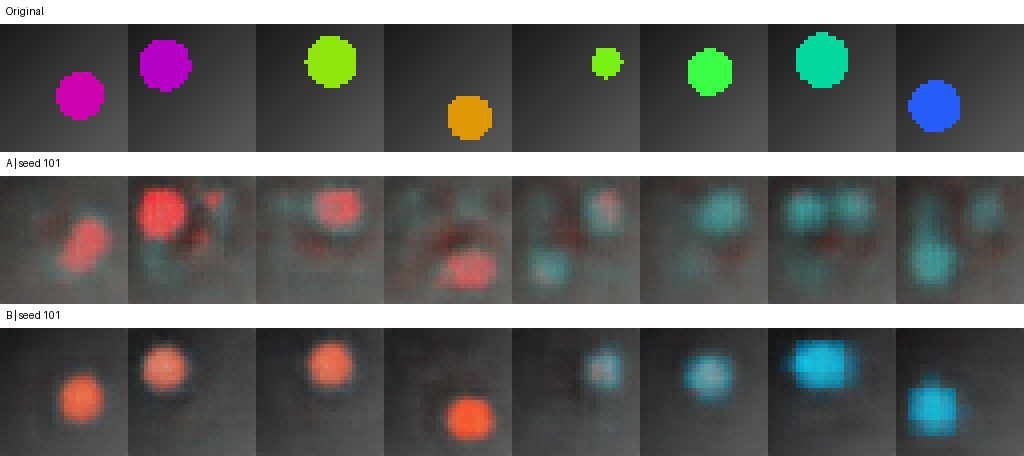

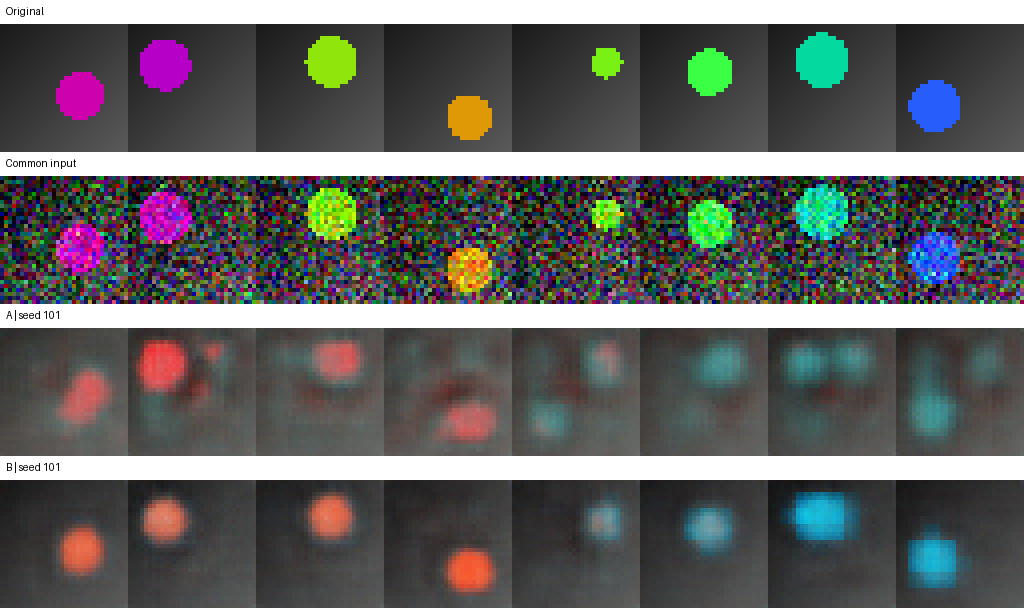

Демонстрационный вариант 1


,metric,A,s,B,delta,ratio,criterion_2s,statistical_applicable,change_percent,practical_limit,practical
0,psnr,26.129395,0.851753,23.187636,-2.941759,3.453770,True,True,-11.258427,1.000000,deterioration
1,gap,0.041924,0.009044,0.098849,0.056926,6.294461,True,True,135.783114,0.100000,neutral
2,params,101.035000,0.000000,88.741000,-12.294000,NaN,True,False,-12.168061,NaN,changed
3,seconds,1.859956,0.043740,1.827037,-0.032920,0.752622,False,True,-1.769915,0.371991,neutral


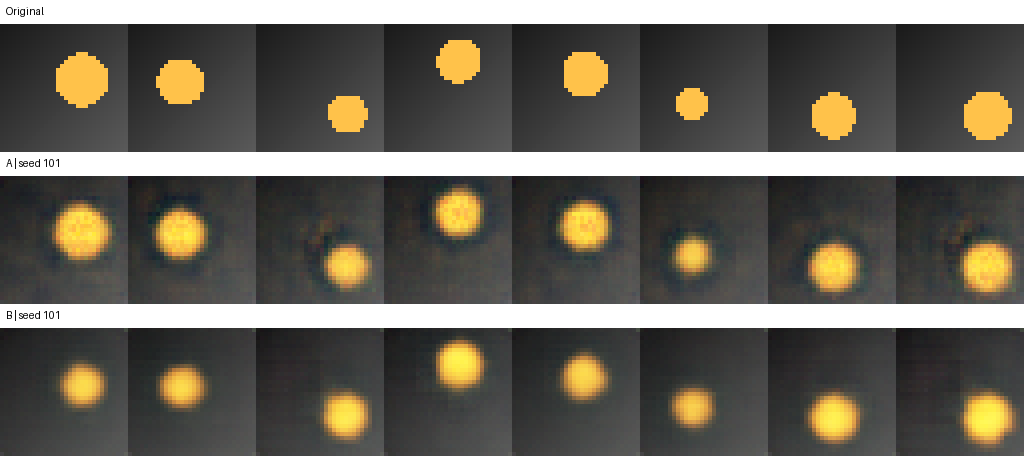

In [6]:
import json
import pandas as pd
from PIL import Image
from IPython.display import display

for filename in ('measurements.csv', 'summary.csv', 'latent_summary.csv'):
    print(filename)
    display(pd.read_csv(result_dir / filename))
print('Эталон и зашумлённый вход')
print((result_dir / 'baseline.json').read_text())
print('Удвоенные допуски')
display(pd.DataFrame(json.loads((result_dir / 'sensitivity_double_tolerance.json').read_text())))
display(Image.open(result_dir / 'comparison.png'))
display(Image.open(result_dir / 'comparison_with_input.png'))
print('Демонстрационный вариант 1')
display(pd.read_csv(result_dir / 'demo_variant1/summary.csv'))
display(Image.open(result_dir / 'demo_variant1/comparison.png'))


## 7. Сохранение
ZIP включает папку запуска с измерениями, реконструкциями, весами моделей для seed 101 и паспортом. Выполненный блокнот сохраняется отдельно в IPYNB вместе с выводом ячеек.


In [7]:
import shutil
from google.colab import files
archive = shutil.make_archive(str(result_dir), 'zip', root_dir=result_dir.parent, base_dir=result_dir.name)
print(archive)
files.download(archive)


/content/LR07/artifacts/v23_20261015_170113_333088.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>